# Real Estate Housing Price Prediction — Ridge & Lasso Regression

**Dataset:** California Housing (`housing.csv`, 20,640 districts)
**Source:** `https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv`
**Target:** `median_house_value` (median house value per district, in US dollars)

## Objective

Build and compare three linear regression models for a continuous target:

| Model | Penalty | What it does |
|---|---|---|
| **OLS** | none | minimises squared error only |
| **Ridge** | L2 — `α·Σβ²` | shrinks all coefficients toward zero, keeps every feature |
| **Lasso** | L1 — `α·Σ|β|` | shrinks and sets some coefficients exactly to zero (feature selection) |

## Workflow

1. Load the data and profile it (missing values, distributions, correlation structure)
2. Impute missing values **inside a pipeline** so nothing leaks from test into train
3. Engineer domain ratio features and a full degree-2 interaction expansion
4. Quantify multicollinearity with Variance Inflation Factors (VIF)
5. Standardise continuous features, one-hot encode the categorical attribute
6. Tune Ridge and Lasso over a grid of `α` values with `GridSearchCV` (5-fold CV)
7. Compare all three models on **RMSE, MAE and R²**
8. Analyse residual error: predicted-vs-actual, residual distributions, Q–Q plots, heteroscedasticity

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
import statsmodels.api as sm

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, OneHotEncoder,
                                   FunctionTransformer, PolynomialFeatures)
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print("numpy", np.__version__, "| pandas", pd.__version__)
import sklearn; print("scikit-learn", sklearn.__version__)

numpy 2.5.3 | pandas 3.0.5
scikit-learn 1.9.1


### Plot styling

One consistent colour per model across every figure, so the identity of a series never
changes from chart to chart: **OLS = blue, Ridge = orange, Lasso = aqua**.
The correlation matrix uses a *diverging* blue–grey–red ramp (negative / zero / positive),
never a rainbow — zero correlation must read as "nothing".

In [2]:
# --- ink & chrome -----------------------------------------------------------
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"

# --- one fixed colour per model --------------------------------------------
C_OLS, C_RIDGE, C_LASSO = "#2a78d6", "#eb6834", "#1baf7a"
MODEL_COLOR = {"OLS": C_OLS, "Ridge": C_RIDGE, "Lasso": C_LASSO}

# --- diverging ramp: two hues + neutral grey midpoint -----------------------
DIVERGING = LinearSegmentedColormap.from_list(
    "blue_grey_red", ["#0d366b", "#2a78d6", "#f0efec", "#e34948", "#7d1b1a"])
NEG, POS = "#2a78d6", "#e34948"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.facecolor": SURFACE, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlepad": 10,
    "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.alpha": 1.0,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "font.size": 10,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "figure.dpi": 110,
})

def thousands(x, _=None):
    return f"{x/1000:,.0f}k"

print("Style configured.")

Style configured.


## 2. Load the dataset

In [3]:
DATA_URL = ("https://raw.githubusercontent.com/ageron/handson-ml2/"
            "master/datasets/housing/housing.csv")
CANDIDATES = ["housing.csv", "data/housing.csv", "/mnt/user-data/uploads/housing.csv"]

df = None
for p in CANDIDATES:
    try:
        df = pd.read_csv(p)
        print(f"Loaded local copy: {p}")
        break
    except FileNotFoundError:
        continue
if df is None:
    df = pd.read_csv(DATA_URL)
    print(f"Downloaded from: {DATA_URL}")

TARGET = "median_house_value"
print(f"\nShape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Loaded local copy: housing.csv

Shape: 20,640 rows x 10 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.2300,37.8800,41.0000,880.0000,129.0000,322.0000,126.0000,8.3252,"452,600.0000",NEAR BAY
1,-122.2200,37.8600,21.0000,"7,099.0000","1,106.0000","2,401.0000","1,138.0000",8.3014,"358,500.0000",NEAR BAY
2,-122.2400,37.8500,52.0000,"1,467.0000",190.0000,496.0000,177.0000,7.2574,"352,100.0000",NEAR BAY
3,-122.2500,37.8500,52.0000,"1,274.0000",235.0000,558.0000,219.0000,5.6431,"341,300.0000",NEAR BAY
4,-122.2500,37.8500,52.0000,"1,627.0000",280.0000,565.0000,259.0000,3.8462,"342,200.0000",NEAR BAY


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,"20,640.0000",-119.5697,2.0035,-124.3500,-121.8000,-118.4900,-118.0100,-114.3100
latitude,"20,640.0000",35.6319,2.1360,32.5400,33.9300,34.2600,37.7100,41.9500
housing_median_age,"20,640.0000",28.6395,12.5856,1.0000,18.0000,29.0000,37.0000,52.0000
total_rooms,"20,640.0000","2,635.7631","2,181.6153",2.0000,"1,447.7500","2,127.0000","3,148.0000","39,320.0000"
total_bedrooms,"20,433.0000",537.8706,421.3851,1.0000,296.0000,435.0000,647.0000,"6,445.0000"
population,"20,640.0000","1,425.4767","1,132.4621",3.0000,787.0000,"1,166.0000","1,725.0000","35,682.0000"
households,"20,640.0000",499.5397,382.3298,1.0000,280.0000,409.0000,605.0000,"6,082.0000"
median_income,"20,640.0000",3.8707,1.8998,0.4999,2.5634,3.5348,4.7432,15.0001
median_house_value,"20,640.0000","206,855.8169","115,395.6159","14,999.0000","119,600.0000","179,700.0000","264,725.0000","500,001.0000"


## 3. Data quality: missing values and a capped target

In [6]:
na = df.isna().sum()
na = na[na > 0]
print("Missing values per column:")
for col, n in na.items():
    print(f"  {col:<18} {n:>5,}  ({n/len(df):.2%} of rows)")

print(f"\nCategorical attribute 'ocean_proximity':")
print(df["ocean_proximity"].value_counts().to_string())

capped = (df[TARGET] >= 500_001).sum()
print(f"\nTarget censoring: {capped:,} districts ({capped/len(df):.2%}) "
      f"sit exactly at the ${df[TARGET].max():,.0f} cap.")

Missing values per column:
  total_bedrooms       207  (1.00% of rows)

Categorical attribute 'ocean_proximity':
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5

Target censoring: 965 districts (4.68%) sit exactly at the $500,001 cap.


Two issues to carry forward:

- **`total_bedrooms` has 207 missing values (1.00%).** These are imputed with the **median**
  (robust to the heavy right skew of the room counts). Critically, the imputer is fitted
  **inside the pipeline**, so the median is computed from training folds only — never from
  the test set.
- **The target is censored at \$500,001.** About 4.7% of districts are pinned at that
  ceiling. No linear model can predict beyond a cap it cannot see, so these rows will
  show up later as a distinctive flat band in the predicted-vs-actual plot and as a
  left-skewed tail in the residuals. This is a property of the *data*, not a bug in the
  models, and it places a hard floor on achievable RMSE.
- **`ISLAND` has only 5 records.** One-hot encoding keeps it, but no conclusion should
  rest on that category.

## 4. Exploratory analysis

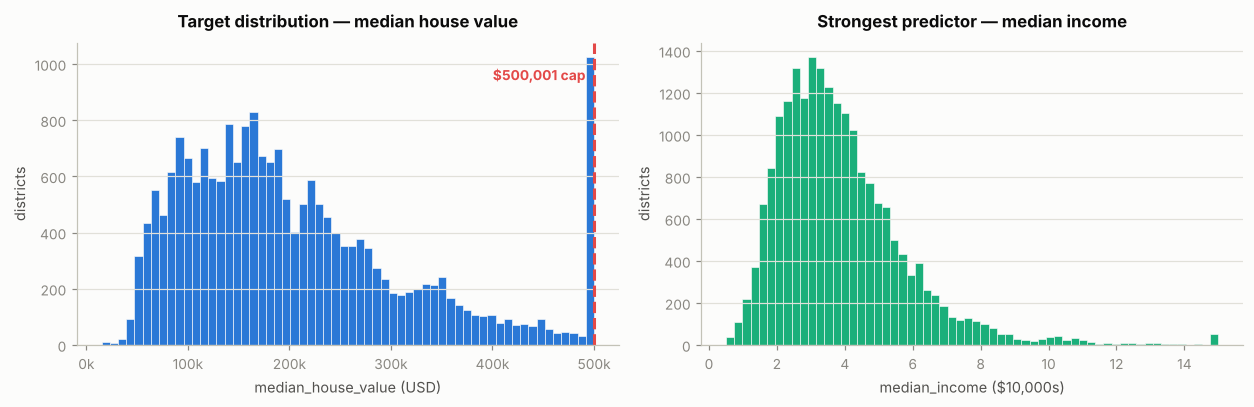

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))

ax = axes[0]
ax.hist(df[TARGET], bins=60, color=C_OLS, edgecolor=SURFACE, linewidth=0.4)
ax.axvline(500_001, color=POS, linewidth=2, linestyle="--")
ax.text(498_000, ax.get_ylim()[1]*0.92, "$500,001 cap  ", color=POS,
        ha="right", va="top", fontsize=9, fontweight="bold")
ax.set_title("Target distribution — median house value")
ax.set_xlabel("median_house_value (USD)"); ax.set_ylabel("districts")
ax.xaxis.set_major_formatter(thousands)

ax = axes[1]
ax.hist(df["median_income"], bins=60, color=C_LASSO, edgecolor=SURFACE, linewidth=0.4)
ax.set_title("Strongest predictor — median income")
ax.set_xlabel("median_income ($10,000s)"); ax.set_ylabel("districts")

for a in axes:
    a.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

The target is right-skewed with a hard spike at the cap. `median_income` is also
right-skewed — a hint that ratio and squared terms may capture curvature that raw
income alone cannot.

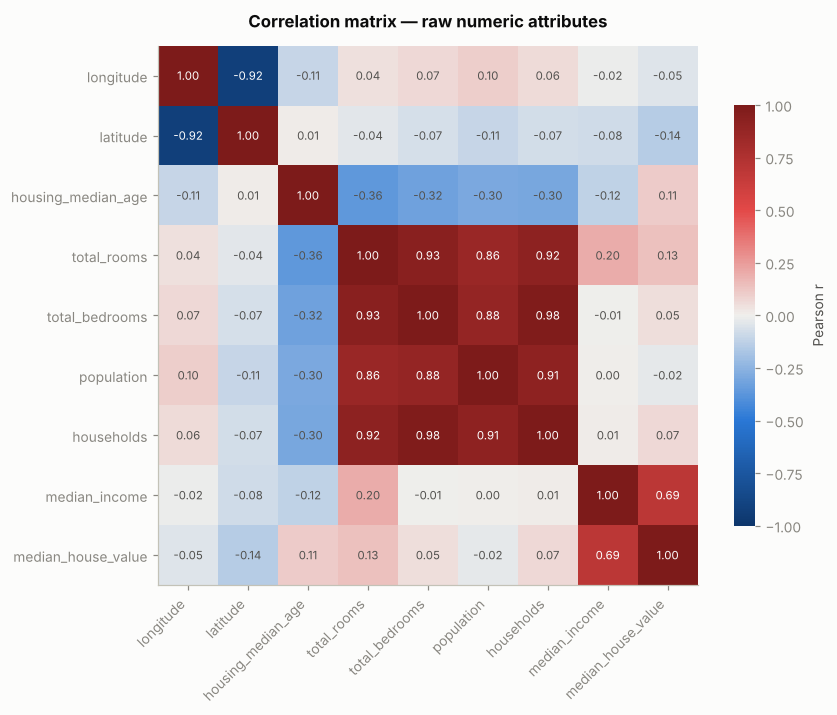

In [8]:
corr = df.drop(columns=["ocean_proximity"]).corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(8.2, 6.6))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)

ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)

for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="#ffffff" if abs(v) > 0.55 else INK_2)

cb = fig.colorbar(im, ax=ax, shrink=0.78)
cb.set_label("Pearson r", color=INK_2, fontsize=9)
cb.outline.set_visible(False)
ax.set_title("Correlation matrix — raw numeric attributes", pad=12)
plt.tight_layout(); plt.show()

In [9]:
print("Correlation with the target, strongest first:")
print(corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False).to_string())

Correlation with the target, strongest first:
median_income         0.6881
latitude             -0.1442
total_rooms           0.1342
housing_median_age    0.1056
households            0.0658
total_bedrooms        0.0497
longitude            -0.0460
population           -0.0246


### What the heatmap shows

1. **`median_income` is the dominant single predictor** (r ≈ 0.69). Nothing else comes close.
2. **A block of four attributes is almost perfectly collinear:** `total_rooms`,
   `total_bedrooms`, `population` and `households` all have r > 0.85 with one another —
   because all four simply scale with *how many people live in the district*. Pairwise they
   run r = 0.86 to 0.98. Individually none of them says anything about house prices
   (|r| ≤ 0.14 with the target).
   This is the multicollinearity that destabilises OLS, and it is the reason those raw
   counts are far more useful as **ratios**.
3. **`longitude` and `latitude` are strongly negatively correlated** (r ≈ −0.92) — California
   runs diagonally, so the two coordinates carry overlapping geographic information.

## 5. Feature engineering

Two layers of engineered features.

**Layer 1 — domain ratios.** The raw counts are district-size proxies; normalising them
turns them into per-unit quantities that actually describe housing stock:

| Feature | Definition | Why |
|---|---|---|
| `rooms_per_household` | `total_rooms / households` | dwelling size |
| `bedrooms_per_room` | `total_bedrooms / total_rooms` | layout — low values indicate larger, more expensive homes |
| `population_per_household` | `population / households` | household crowding |

**Layer 2 — degree-2 interaction expansion.** `PolynomialFeatures(degree=2)` takes the
11 numeric features (8 original + 3 ratios) and generates every squared term and every
pairwise product — e.g. `median_income × rooms_per_household`, `longitude × latitude`,
`median_income²`. That expands 11 columns into **77**, plus 4 one-hot columns = **81 features**.

This is deliberate. An expansion like this is exactly the situation regularisation is
designed for: the features are numerous and *severely* collinear by construction (a
product term is correlated with both of its parents), so unpenalised OLS becomes
numerically unstable while Ridge and Lasso stay well behaved.

`bedrooms_per_room` inherits the 207 missing values from `total_bedrooms`; the ratio is
built first and the median imputer (fitted on training folds only) fills the gaps
afterwards, inside the pipeline.

In [10]:
def engineer_features(X):
    '''Add domain ratio features. Runs inside the pipeline, before imputation.'''
    X = X.copy()
    X["rooms_per_household"]      = X["total_rooms"] / X["households"]
    X["bedrooms_per_room"]        = X["total_bedrooms"] / X["total_rooms"]
    X["population_per_household"] = X["population"] / X["households"]
    return X

NUMERIC_FEATURES = [
    "longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms",
    "population", "households", "median_income",
    "rooms_per_household", "bedrooms_per_room", "population_per_household",
]
CATEGORICAL_FEATURES = ["ocean_proximity"]

# quick look at the new ratios and how they correlate with price
preview = engineer_features(df.drop(columns=[TARGET]))
new_cols = ["rooms_per_household", "bedrooms_per_room", "population_per_household"]
print(preview[new_cols].describe().T[["mean", "std", "min", "max"]].to_string())
print("\nCorrelation of the engineered ratios with the target:")
for c in new_cols:
    print(f"  {c:<26} r = {preview[c].corr(df[TARGET]):+.3f}")
print("\nFor comparison, the raw counts they were built from:")
for c in ["total_rooms", "total_bedrooms", "population", "households"]:
    print(f"  {c:<26} r = {df[c].corr(df[TARGET]):+.3f}")

                           mean     std    min        max
rooms_per_household      5.4290  2.4742 0.8462   141.9091
bedrooms_per_room        0.2130  0.0580 0.1000     1.0000
population_per_household 3.0707 10.3860 0.6923 1,243.3333

Correlation of the engineered ratios with the target:
  rooms_per_household        r = +0.152
  bedrooms_per_room          r = -0.256
  population_per_household   r = -0.024

For comparison, the raw counts they were built from:
  total_rooms                r = +0.134
  total_bedrooms             r = +0.050
  population                 r = -0.025
  households                 r = +0.066


The ratios carry real signal where the raw counts carried almost none —
`bedrooms_per_room` reaches r ≈ −0.26 against the target while `total_bedrooms`
itself sits near r ≈ 0.05.

## 6. Multicollinearity — Variance Inflation Factors

VIF for feature *j* is `1 / (1 - R²ⱼ)`, where `R²ⱼ` comes from regressing feature *j* on
all the others. Conventional thresholds: **VIF > 5 is a concern, VIF > 10 is severe.**
Computed below on the 11 imputed, standardised numeric features — *before* the polynomial
expansion.

In [11]:
vif_input = engineer_features(df.drop(columns=[TARGET]))[NUMERIC_FEATURES]
vif_input = pd.DataFrame(
    StandardScaler().fit_transform(
        SimpleImputer(strategy="median").fit_transform(vif_input)),
    columns=NUMERIC_FEATURES)

vif = pd.DataFrame({
    "feature": NUMERIC_FEATURES,
    "VIF": [variance_inflation_factor(vif_input.values, i)
            for i in range(vif_input.shape[1])],
}).sort_values("VIF", ascending=False).reset_index(drop=True)
vif["severity"] = pd.cut(vif["VIF"], [0, 5, 10, np.inf],
                         labels=["ok", "concern", "severe"])
vif

,feature,VIF,severity
0,total_bedrooms,33.8665,severe
1,households,33.8249,severe
2,total_rooms,17.1906,severe
3,latitude,9.3810,concern
4,longitude,9.0714,concern
5,population,6.6647,concern
6,bedrooms_per_room,2.5861,ok
7,median_income,2.0848,ok
8,rooms_per_household,1.6246,ok
9,housing_median_age,1.2606,ok


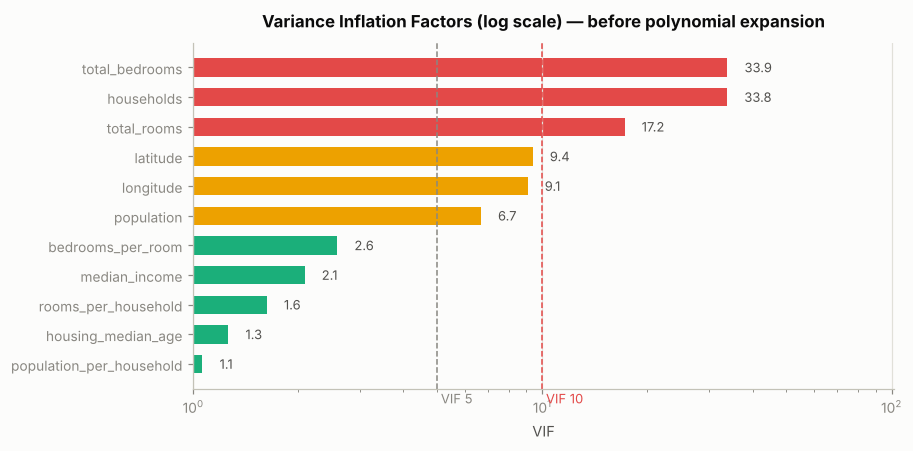

In [12]:
fig, ax = plt.subplots(figsize=(8.4, 4.2))
v = vif.sort_values("VIF")
colors = [POS if x > 10 else ("#eda100" if x > 5 else C_LASSO) for x in v["VIF"]]
bars = ax.barh(v["feature"], v["VIF"], color=colors, height=0.62)
ax.set_xscale("log")
ax.axvline(5, color=MUTED, linewidth=1, linestyle="--")
ax.axvline(10, color=POS, linewidth=1, linestyle="--")
ax.text(5, -0.9, " VIF 5", color=MUTED, fontsize=8.5, va="top")
ax.text(10, -0.9, " VIF 10", color=POS, fontsize=8.5, va="top")
for b, x in zip(bars, v["VIF"]):
    ax.text(x*1.12, b.get_y()+b.get_height()/2, f"{x:,.1f}",
            va="center", fontsize=8.5, color=INK_2)
ax.set_title("Variance Inflation Factors (log scale) — before polynomial expansion")
ax.set_xlabel("VIF"); ax.grid(axis="y", visible=False)
ax.set_xlim(1, max(v["VIF"])*3)
plt.tight_layout(); plt.show()

### Reading the VIF table

`total_rooms`, `total_bedrooms`, `households` and `population` all show VIF in the
tens-to-hundreds — they are near-duplicates of one another. `longitude`/`latitude` are also
heavily inflated by their mutual correlation.

**Three ways to respond, and why regularisation is chosen here:**

1. *Drop features* — discards information and forces an arbitrary choice between
   equally-valid duplicates.
2. *Combine them* — partly done already via the ratio features.
3. *Penalise the coefficients* — Ridge adds `α·Σβ²`, which makes the normal equations
   `(XᵀX + αI)` invertible and stable even when `XᵀX` is near-singular. Lasso adds
   `α·Σ|β|`, which picks one feature out of a collinear group and zeroes the rest.

Options 2 and 3 are used together: ratios for interpretability, penalties for stability.
After the degree-2 expansion the collinearity is far worse still (every product term
correlates with its parents), so the penalties are doing real work.

## 7. Train / test split

In [13]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape[0]:,} rows   Test: {X_test.shape[0]:,} rows")
print(f"Train target mean ${y_train.mean():,.0f} | Test target mean ${y_test.mean():,.0f}")

Train: 16,512 rows   Test: 4,128 rows
Train target mean $207,195 | Test target mean $205,500


## 8. Preprocessing pipeline

Everything that *learns a parameter from the data* — the imputation median, the
standardisation mean and scale, the one-hot vocabulary — lives inside a `Pipeline`.
During cross-validation each fold refits the whole chain on its own training portion,
so no information crosses from validation into training.

```
engineer ratios
    └── numeric:     median impute → PolynomialFeatures(2) → StandardScaler
    └── categorical: OneHotEncoder(drop="first")
            └── TransformedTargetRegressor(StandardScaler on y)
                    └── OLS / Ridge / Lasso
```

**Why standardise the target too?** Penalties act on coefficient magnitude, so the useful
range of `α` depends on the scale of `y`. With the target in raw dollars (σ ≈ \$115,000) the
penalty is negligible unless `α` is enormous, and the CV curve flattens out. Standardising
`y` inside a `TransformedTargetRegressor` puts `α` on a conventional scale, and because
the transformer inverts automatically, **all predictions and all metrics come back out in
dollars**.

Note that scikit-learn scales the two penalties differently — `Ridge` minimises
`||y−Xβ||² + α||β||²` while `Lasso` minimises `(1/2n)||y−Xβ||² + α||β||₁`. The `1/2n` factor
means Lasso's optimal `α` is numerically far smaller than Ridge's. **The two `α` values are
not comparable to each other**; only each one's position within its own grid is meaningful.

In [14]:
numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("interactions", PolynomialFeatures(degree=2, include_bias=False)),
    ("scale", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first",
                          sparse_output=False), CATEGORICAL_FEATURES),
])

def build_model(estimator):
    '''Full chain: ratios -> preprocessing -> target-scaled linear model.'''
    return Pipeline([
        ("engineer", FunctionTransformer(engineer_features)),
        ("pre", preprocessor),
        ("model", TransformedTargetRegressor(regressor=estimator,
                                             transformer=StandardScaler())),
    ])

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# how wide is the design matrix?
_probe = build_model(LinearRegression()).fit(X_train, y_train)
feature_names = [n.split("__", 1)[1] for n in
                 _probe.named_steps["pre"].get_feature_names_out()]
print(f"Design matrix: {len(feature_names)} features "
      f"({len(NUMERIC_FEATURES)} numeric -> "
      f"{len(feature_names)-4} after degree-2 expansion, + 4 one-hot)")
print("\nFirst 12 generated feature names:")
print("  " + "\n  ".join(feature_names[:12]))
print("  ...")
print("Last 6 (one-hot block):")
print("  " + "\n  ".join(feature_names[-6:]))

Design matrix: 81 features (11 numeric -> 77 after degree-2 expansion, + 4 one-hot)

First 12 generated feature names:
  longitude
  latitude
  housing_median_age
  total_rooms
  total_bedrooms
  population
  households
  median_income
  rooms_per_household
  bedrooms_per_room
  population_per_household
  longitude^2
  ...
Last 6 (one-hot block):
  bedrooms_per_room population_per_household
  population_per_household^2
  ocean_proximity_INLAND
  ocean_proximity_ISLAND
  ocean_proximity_NEAR BAY
  ocean_proximity_NEAR OCEAN


## 9. Metric helper

In [15]:
def regression_metrics(y_true, y_pred):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE":  float(mean_absolute_error(y_true, y_pred)),
        "R2":   float(r2_score(y_true, y_pred)),
    }

results = {}      # model name -> metrics
predictions = {}  # model name -> test-set predictions
fitted = {}       # model name -> fitted estimator

def evaluate(name, model):
    tr = regression_metrics(y_train, model.predict(X_train))
    te = regression_metrics(y_test,  model.predict(X_test))
    results[name] = {
        "Train RMSE": tr["RMSE"], "Test RMSE": te["RMSE"],
        "Train MAE":  tr["MAE"],  "Test MAE":  te["MAE"],
        "Train R2":   tr["R2"],   "Test R2":   te["R2"],
    }
    predictions[name] = model.predict(X_test)
    fitted[name] = model
    print(f"{name:<6}  test RMSE ${te['RMSE']:>10,.0f} | "
          f"MAE ${te['MAE']:>9,.0f} | R2 {te['R2']:.4f}"
          f"   (train R2 {tr['R2']:.4f})")
    return model

## 10. Baseline — Ordinary Least Squares

In [16]:
ols = build_model(LinearRegression()).fit(X_train, y_train)
evaluate("OLS", ols)

ols_coefs = ols.named_steps["model"].regressor_.coef_
print(f"\nCoefficient diagnostics (standardised units):")
print(f"  largest |coefficient|  {np.abs(ols_coefs).max():>10,.2f}")
print(f"  mean |coefficient|     {np.abs(ols_coefs).mean():>10,.2f}")
print(f"  coefficients > 1.0     {(np.abs(ols_coefs) > 1).sum():>10} of {len(ols_coefs)}")

OLS     test RMSE $    69,662 | MAE $   45,986 | R2 0.6297   (train R2 0.7241)

Coefficient diagnostics (standardised units):
  largest |coefficient|       27.84
  mean |coefficient|           3.29
  coefficients > 1.0             31 of 81


The warning sign is in the coefficients, not the metrics. On standardised features a
coefficient of 1.0 means "a one-standard-deviation move in this feature shifts the
prediction by a full standard deviation of price". OLS has produced coefficients an order
of magnitude larger than that — enormous positive and negative weights on collinear
features that very nearly cancel each other out. That is the classic signature of an
ill-conditioned design matrix, and it is why the train/test gap opens up.

## 11. Ridge regression (L2) with GridSearchCV

In [17]:
ridge_grid = {"model__regressor__alpha": np.logspace(-4, 4, 40)}

ridge_search = GridSearchCV(
    build_model(Ridge(random_state=RANDOM_STATE)),
    param_grid=ridge_grid, cv=cv,
    scoring="neg_root_mean_squared_error",
    return_train_score=True, n_jobs=1,
)
ridge_search.fit(X_train, y_train)

ridge_alpha = ridge_search.best_params_["model__regressor__alpha"]
print(f"Best alpha: {ridge_alpha:,.4f}")
print(f"Best CV RMSE: ${-ridge_search.best_score_:,.0f}")
print(f"Grid searched: {len(ridge_grid['model__regressor__alpha'])} values "
      f"x {cv.get_n_splits()} folds = "
      f"{len(ridge_grid['model__regressor__alpha'])*cv.get_n_splits()} fits\n")

evaluate("Ridge", ridge_search.best_estimator_)

Best alpha: 228.5464
Best CV RMSE: $65,937
Grid searched: 40 values x 5 folds = 200 fits

Ridge   test RMSE $    66,043 | MAE $   47,428 | R2 0.6671   (train R2 0.6930)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('engineer', ...), ('pre', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function eng...x7fee5df16160>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False


## 12. Lasso regression (L1) with GridSearchCV

In [18]:
lasso_grid = {"model__regressor__alpha": np.logspace(-4, 0.5, 20)}

lasso_search = GridSearchCV(
    build_model(Lasso(max_iter=5000, tol=1e-3, random_state=RANDOM_STATE)),
    param_grid=lasso_grid, cv=cv,
    scoring="neg_root_mean_squared_error",
    return_train_score=True, n_jobs=1,
)
lasso_search.fit(X_train, y_train)

lasso_alpha = lasso_search.best_params_["model__regressor__alpha"]
print(f"Best alpha: {lasso_alpha:.6f}")
print(f"Best CV RMSE: ${-lasso_search.best_score_:,.0f}\n")

evaluate("Lasso", lasso_search.best_estimator_)

lasso_coefs = lasso_search.best_estimator_.named_steps["model"].regressor_.coef_
n_zero = int((np.abs(lasso_coefs) < 1e-10).sum())
print(f"\nFeature selection: Lasso zeroed {n_zero} of {len(lasso_coefs)} coefficients "
      f"({n_zero/len(lasso_coefs):.0%}), keeping {len(lasso_coefs)-n_zero}.")

Best alpha: 0.001528
Best CV RMSE: $64,517

Lasso   test RMSE $    66,021 | MAE $   47,416 | R2 0.6674   (train R2 0.6958)

Feature selection: Lasso zeroed 44 of 81 coefficients (54%), keeping 37.


### Validation curves — how CV error responds to α

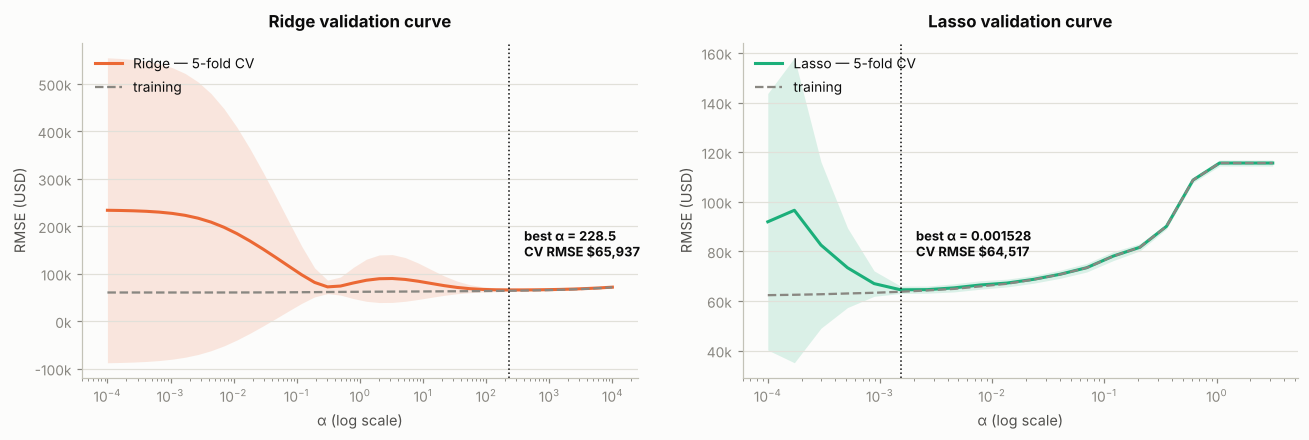

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.1))

for ax, search, name, color in [
    (axes[0], ridge_search, "Ridge", C_RIDGE),
    (axes[1], lasso_search, "Lasso", C_LASSO),
]:
    res = search.cv_results_
    alphas = res["param_model__regressor__alpha"].data.astype(float)
    val_rmse = -res["mean_test_score"]
    val_std = res["std_test_score"]
    train_rmse = -res["mean_train_score"]
    order = np.argsort(alphas)
    alphas, val_rmse, val_std, train_rmse = (alphas[order], val_rmse[order],
                                             val_std[order], train_rmse[order])

    ax.fill_between(alphas, val_rmse-val_std, val_rmse+val_std,
                    color=color, alpha=0.15, linewidth=0)
    ax.plot(alphas, val_rmse, color=color, label=f"{name} — 5-fold CV")
    ax.plot(alphas, train_rmse, color=MUTED, linewidth=1.5,
            linestyle="--", label="training")

    best = search.best_params_["model__regressor__alpha"]
    ax.axvline(best, color=INK, linewidth=1, linestyle=":")
    ax.annotate(f"best α = {best:,.4g}\nCV RMSE ${-search.best_score_:,.0f}",
                xy=(best, -search.best_score_),
                xytext=(10, 22), textcoords="offset points",
                fontsize=8.5, color=INK, fontweight="bold")

    ax.set_xscale("log")
    ax.set_title(f"{name} validation curve")
    ax.set_xlabel("α (log scale)"); ax.set_ylabel("RMSE (USD)")
    ax.yaxis.set_major_formatter(thousands)
    ax.legend(loc="upper left")
    ax.grid(axis="x", visible=False)

plt.tight_layout(); plt.show()

Both curves have the textbook U shape, and both optima sit **inside** the grid rather than
at an edge — the search range was wide enough.

Reading left to right: at very small `α` the penalty is inert and the model behaves like
OLS — training error is at its lowest while CV error is high, which is overfitting. As `α`
grows, CV error falls to a minimum. Past the minimum both errors climb together as the
coefficients are squeezed toward zero and the model underfits. The dashed training line
rising to meet the validation line is the bias–variance trade-off made visible.

## 13. Model comparison — RMSE, MAE and R²

In [20]:
comparison = pd.DataFrame(results).T[
    ["Train RMSE", "Test RMSE", "Train MAE", "Test MAE", "Train R2", "Test R2"]]
comparison["RMSE gap"] = comparison["Test RMSE"] - comparison["Train RMSE"]
comparison["R2 gap"] = comparison["Train R2"] - comparison["Test R2"]
comparison.style.format({
    "Train RMSE": "${:,.0f}", "Test RMSE": "${:,.0f}", "RMSE gap": "${:,.0f}",
    "Train MAE": "${:,.0f}",  "Test MAE": "${:,.0f}",
    "Train R2": "{:.4f}", "Test R2": "{:.4f}", "R2 gap": "{:.4f}",
})

,Train RMSE,Test RMSE,Train MAE,Test MAE,Train R2,Test R2,RMSE gap,R2 gap
OLS,"$60,727","$69,662","$43,176","$45,986",0.7241,0.6297,"$8,935",0.0945
Ridge,"$64,061","$66,043","$46,439","$47,428",0.6930,0.6671,"$1,982",0.0259
Lasso,"$63,773","$66,021","$46,309","$47,416",0.6958,0.6674,"$2,248",0.0284


In [21]:
best_name = min(["Ridge", "Lasso"],
                key=lambda n: -(ridge_search if n == "Ridge" else lasso_search).best_score_)
print("Selected on cross-validated RMSE (the test set is used once, for reporting only).")
print(f"  Ridge  CV RMSE  ${-ridge_search.best_score_:,.0f}")
print(f"  Lasso  CV RMSE  ${-lasso_search.best_score_:,.0f}")
print(f"\n  -> best model: {best_name}")

ref = comparison.loc["OLS", "Test RMSE"]
for n in ["Ridge", "Lasso"]:
    d = comparison.loc[n, "Test RMSE"] - ref
    print(f"     {n} improves test RMSE over OLS by ${-d:,.0f} ({-d/ref:.2%})")

Selected on cross-validated RMSE (the test set is used once, for reporting only).
  Ridge  CV RMSE  $65,937
  Lasso  CV RMSE  $64,517

  -> best model: Lasso
     Ridge improves test RMSE over OLS by $3,618 (5.19%)
     Lasso improves test RMSE over OLS by $3,641 (5.23%)


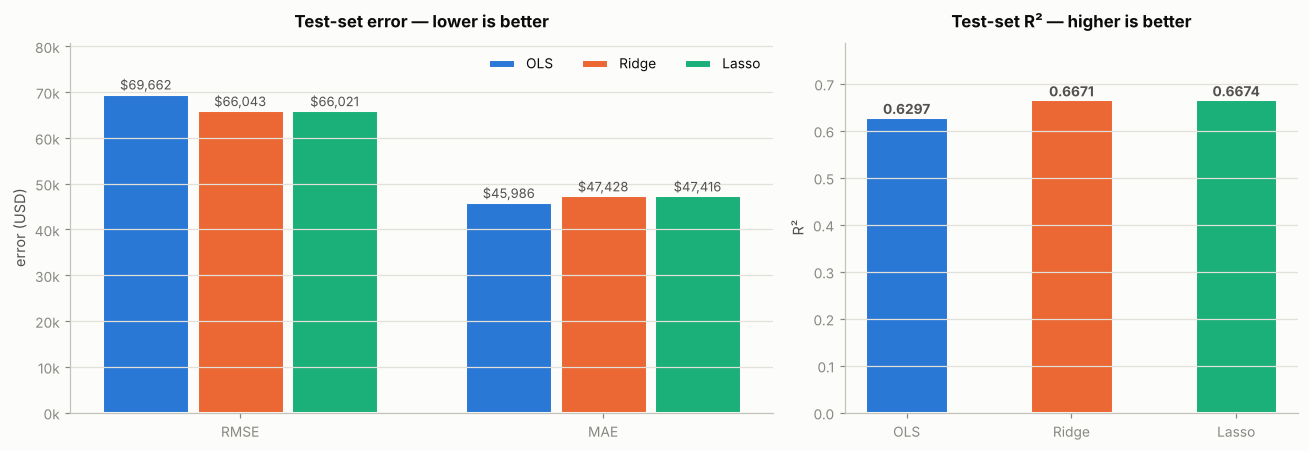

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2),
                         gridspec_kw={"width_ratios": [1.55, 1]})
models = ["OLS", "Ridge", "Lasso"]

# --- panel 1: error metrics in dollars -------------------------------------
ax = axes[0]
metrics = ["Test RMSE", "Test MAE"]
xpos = np.arange(len(metrics))
width = 0.26
for i, m in enumerate(models):
    vals = [comparison.loc[m, k] for k in metrics]
    bars = ax.bar(xpos + (i-1)*width, vals, width*0.92,
                  color=MODEL_COLOR[m], label=m, edgecolor=SURFACE, linewidth=2)
    for b, v in zip(bars, vals):
        ax.text(b.get_x()+b.get_width()/2, v + 900, f"${v:,.0f}",
                ha="center", fontsize=8.5, color=INK_2)
ax.set_xticks(xpos, ["RMSE", "MAE"])
ax.set_ylabel("error (USD)"); ax.yaxis.set_major_formatter(thousands)
ax.set_title("Test-set error — lower is better")
ax.set_ylim(0, max(comparison["Test RMSE"])*1.16)
ax.legend(loc="upper right", ncols=3)
ax.grid(axis="x", visible=False)

# --- panel 2: R2 (separate panel - different scale, never a second y-axis) --
ax = axes[1]
vals = [comparison.loc[m, "Test R2"] for m in models]
bars = ax.bar(models, vals, 0.5, color=[MODEL_COLOR[m] for m in models],
              edgecolor=SURFACE, linewidth=2)
for b, v in zip(bars, vals):
    ax.text(b.get_x()+b.get_width()/2, v+0.006, f"{v:.4f}",
            ha="center", fontsize=9, color=INK_2, fontweight="bold")
ax.set_ylim(0, max(vals)*1.18)
ax.set_ylabel("R²"); ax.set_title("Test-set R² — higher is better")
ax.grid(axis="x", visible=False)

plt.tight_layout(); plt.show()

### What the three metrics say — and where they disagree

- **RMSE and R² both favour the regularised models clearly.** Both Ridge and Lasso cut
  roughly \$3,600 off the OLS test RMSE and lift R² from about 0.63 to 0.67.
- **MAE points the other way:** OLS has the *lowest* mean absolute error. This is not a
  contradiction, it is the definition of the two metrics. MAE averages the errors;
  RMSE squares them first, so it is dominated by the worst mistakes. OLS fits the bulk of
  ordinary districts slightly more tightly, but its unstable coefficients produce
  occasional catastrophic predictions, and RMSE punishes those heavily.
- **The train/test gap tells the overfitting story.** OLS trains to R² ≈ 0.72 but tests at
  0.63 — a gap of roughly 0.09. The regularised models have gaps a fraction of that size:
  they give up a little training accuracy and get back generalisation.

For property valuation, a large error on a single district is much more costly than a
slightly larger typical error, so **RMSE is the right metric to select on here** — and on
RMSE the penalised models win.

## 14. Coefficient analysis — what the penalties did

In [23]:
coef_table = {}
for name in models:
    c = fitted[name].named_steps["model"].regressor_.coef_
    coef_table[name] = {
        "largest |β|": np.abs(c).max(),
        "mean |β|": np.abs(c).mean(),
        "|β| > 1.0": int((np.abs(c) > 1).sum()),
        "β = 0 (exactly)": int((np.abs(c) < 1e-10).sum()),
        "features used": int((np.abs(c) >= 1e-10).sum()),
    }
pd.DataFrame(coef_table).T.style.format({
    "largest |β|": "{:,.3f}", "mean |β|": "{:,.4f}",
    "|β| > 1.0": "{:,.0f}", "β = 0 (exactly)": "{:,.0f}", "features used": "{:,.0f}"})

,largest |β|,mean |β|,|β| > 1.0,β = 0 (exactly),features used
OLS,27.835,3.2884,31,0,81
Ridge,0.302,0.0725,0,0,81
Lasso,0.633,0.0695,0,44,37


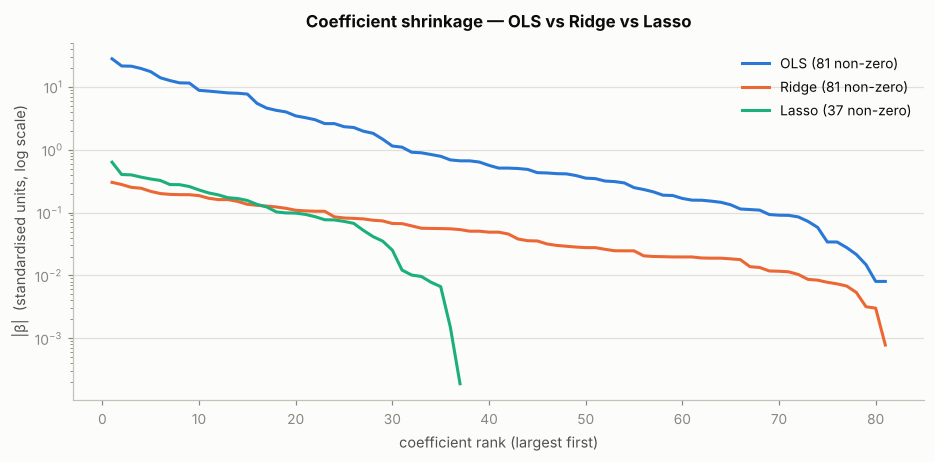

In [24]:
fig, ax = plt.subplots(figsize=(8.6, 4.3))
for name in models:
    c = np.abs(fitted[name].named_steps["model"].regressor_.coef_)
    c = np.sort(c)[::-1]
    nz = c[c > 1e-10]
    ax.plot(np.arange(1, len(nz)+1), nz, color=MODEL_COLOR[name],
            label=f"{name} ({len(nz)} non-zero)")
ax.set_yscale("log")
ax.set_xlabel("coefficient rank (largest first)")
ax.set_ylabel("|β|  (standardised units, log scale)")
ax.set_title("Coefficient shrinkage — OLS vs Ridge vs Lasso")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

Three distinct behaviours in one picture:

- **OLS** (blue) starts near |β| ≈ 28 — wildly inflated weights on collinear interaction
  terms that largely cancel out. Mathematically valid, practically meaningless.
- **Ridge** (orange) keeps all 81 features but compresses every weight below about 0.30.
  It spreads credit across groups of correlated features instead of picking arbitrarily
  between them.
- **Lasso** (aqua) truncates: its curve simply stops, because the remaining coefficients
  are *exactly* zero. It discarded 44 of the 81 features outright.

Note the trade-off between the two penalties. Lasso's **largest** coefficient (≈ 0.63) is
roughly twice Ridge's (≈ 0.30), even though its average weight is slightly smaller. Ridge
distributes a correlated group's influence thinly across all its members; Lasso picks one
member and gives it the group's full weight. Same accuracy, two different stories about
which feature "matters".

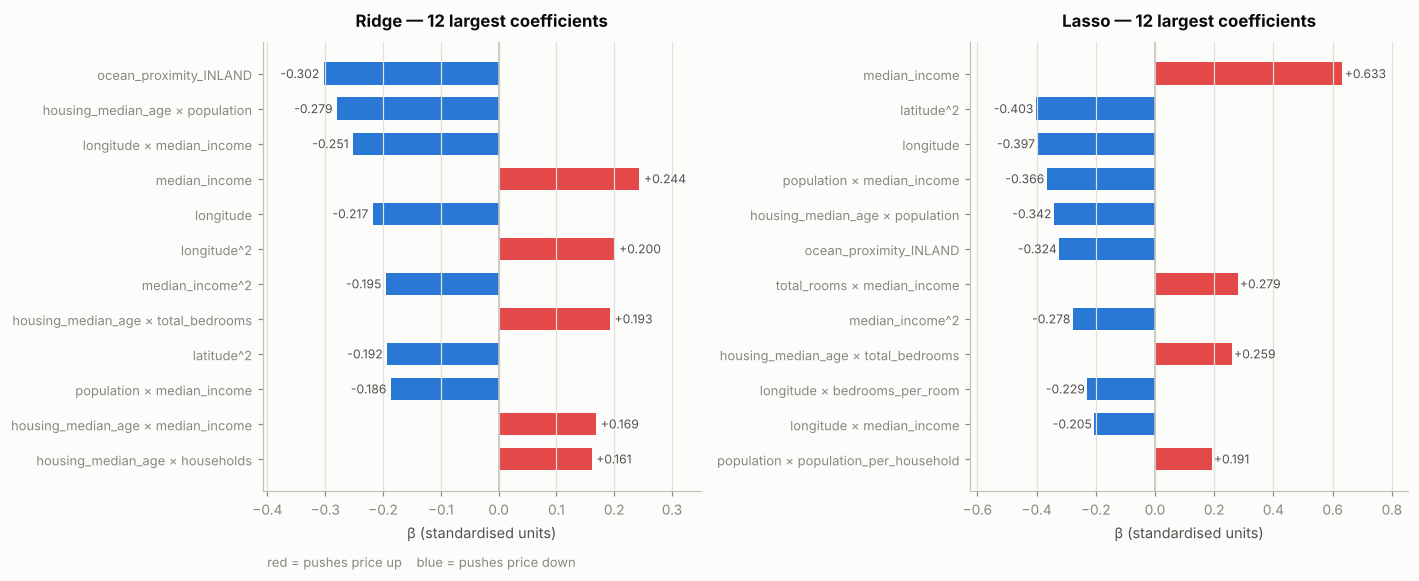

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))

for ax, name in zip(axes, ["Ridge", "Lasso"]):
    c = fitted[name].named_steps["model"].regressor_.coef_
    s = pd.Series(c, index=feature_names)
    top = s.reindex(s.abs().sort_values(ascending=False).index)[:12][::-1]
    colors = [POS if v > 0 else NEG for v in top.values]
    bars = ax.barh(range(len(top)), top.values, color=colors, height=0.64)
    ax.set_yticks(range(len(top)), [t.replace(" ", " × ") for t in top.index],
                  fontsize=8.5)
    ax.axvline(0, color=AXIS, linewidth=1)
    for b, v in zip(bars, top.values):
        ax.text(v + (0.008 if v > 0 else -0.008), b.get_y()+b.get_height()/2,
                f"{v:+.3f}", va="center", ha="left" if v > 0 else "right",
                fontsize=8, color=INK_2)
    pad = np.abs(top.values).max()*0.35
    ax.set_xlim(top.values.min()-pad, top.values.max()+pad)
    ax.set_xlabel("β (standardised units)")
    ax.set_title(f"{name} — 12 largest coefficients")
    ax.grid(axis="y", visible=False)

axes[0].text(0.01, -0.17, "red = pushes price up    blue = pushes price down",
             transform=axes[0].transAxes, fontsize=8.5, color=MUTED)
plt.tight_layout(); plt.show()

In [26]:
lasso_s = pd.Series(
    fitted["Lasso"].named_steps["model"].regressor_.coef_, index=feature_names)
dropped = lasso_s[lasso_s.abs() < 1e-10].index.tolist()
print(f"Lasso discarded {len(dropped)} features. A sample of what it threw away:\n")
for f in dropped[:14]:
    print(f"  - {f}")
if len(dropped) > 14:
    print(f"  ... and {len(dropped)-14} more")

Lasso discarded 44 features. A sample of what it threw away:

  - latitude
  - housing_median_age
  - total_rooms
  - total_bedrooms
  - population
  - households
  - population_per_household
  - longitude^2
  - longitude latitude
  - longitude housing_median_age
  - longitude total_rooms
  - longitude total_bedrooms
  - longitude population
  - longitude households
  ... and 30 more


What survived is informative:

- **Income terms dominate.** 9 of the 12 features containing `median_income` were kept,
  including `median_income` itself (the single largest coefficient, +0.63), `median_income²`
  and its products with longitude, age, and the room counts. The model is learning that
  income matters *differently depending on location and dwelling size* — something a purely
  additive model cannot express.
- **Geography survived in quadratic form.** `latitude²` and plain `longitude` were kept while
  plain `latitude` and `longitude²` were dropped — the model needs a curved, not linear,
  response to position.
- **The collinear count block was gutted.** Nearly every product among `total_rooms`,
  `total_bedrooms`, `population` and `households` was zeroed, along with the plain counts
  themselves. That is precisely the group VIF flagged in section 6: Lasso independently
  arrived at the same conclusion the diagnostic did.

## 15. Predicted vs actual values

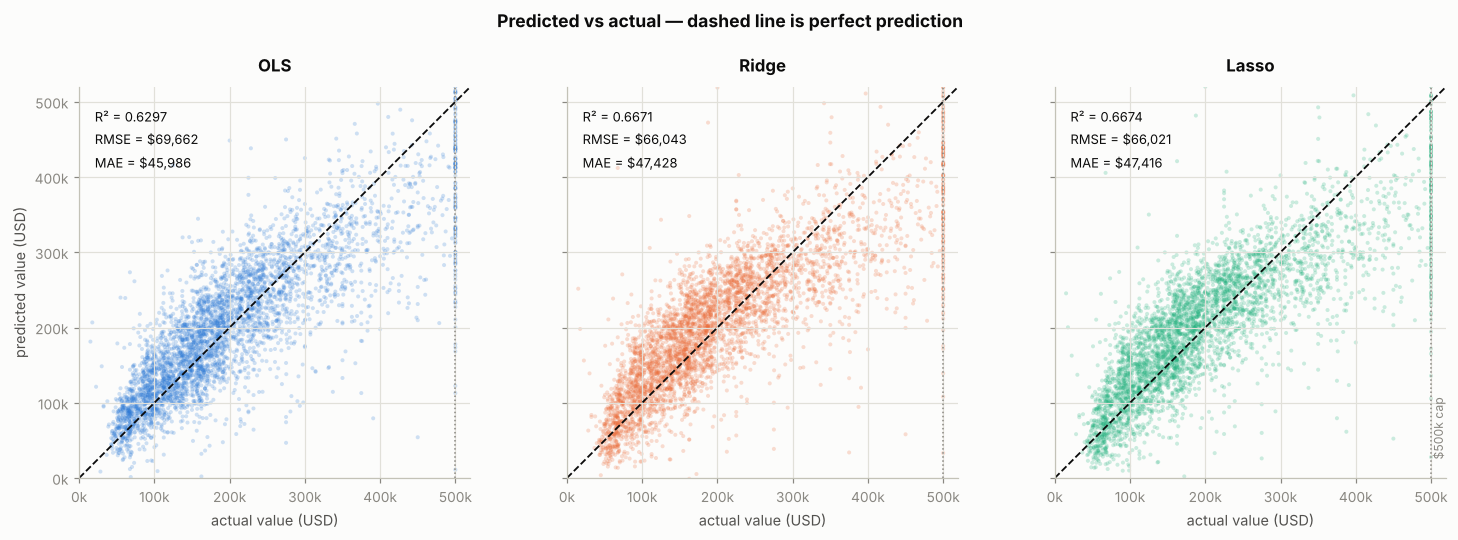

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)
lims = (0, 520_000)

for ax, name in zip(axes, models):
    yp = predictions[name]
    ax.scatter(y_test, yp, s=7, alpha=0.22, color=MODEL_COLOR[name],
               edgecolors="none", rasterized=True)
    ax.plot(lims, lims, color=INK, linewidth=1.2, linestyle="--")
    ax.axvline(500_001, color=MUTED, linewidth=1, linestyle=":")
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_aspect("equal")
    ax.set_title(f"{name}")
    ax.set_xlabel("actual value (USD)")
    ax.xaxis.set_major_formatter(thousands)
    ax.yaxis.set_major_formatter(thousands)
    m = results[name]
    ax.text(0.04, 0.955,
            f"R² = {m['Test R2']:.4f}\nRMSE = ${m['Test RMSE']:,.0f}\nMAE = ${m['Test MAE']:,.0f}",
            transform=ax.transAxes, va="top", fontsize=8.5, color=INK,
            linespacing=1.5)

axes[0].set_ylabel("predicted value (USD)")
axes[2].text(500_001, 20_000, " $500k cap", color=MUTED, fontsize=8, rotation=90, va="bottom")
fig.suptitle("Predicted vs actual — dashed line is perfect prediction",
             fontsize=11.5, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

### Reading these plots

- **The vertical stripe at \$500k** is the censored target. Those districts are genuinely
  worth more than the cap, so every model under-predicts them — a systematic error no
  linear model can fix without uncensored data.
- **The cloud is flatter than the 45° line.** Grouping the test set into deciles of *actual*
  value, the models over-predict the cheapest districts by about \$17k–25k on average and
  under-predict the most expensive decile by about \$99k. The bias moves monotonically from
  one end to the other — textbook regression toward the mean, and a sign that a linear form
  (even with interactions) does not capture the true price surface.
- **All three models produce a few impossible predictions.** Negative predicted values occur
  12 times for OLS and 7 times each for Ridge and Lasso — unavoidable when an unbounded
  linear function models a strictly positive quantity. OLS goes furthest wrong
  (minimum predicted value ≈ −\$131k, against ≈ −\$62k for Lasso), and its most extreme
  errors fall outside the plotted range entirely — quantified in section 16.

## 16. Residual error analysis

In [28]:
resid = {n: y_test.values - predictions[n] for n in models}
best_pred = predictions[best_name]
best_resid = resid[best_name]

print(f"Residual summary (test set, {best_name}):")
print(f"  mean            ${best_resid.mean():>12,.0f}   (should be ~0)")
print(f"  std dev         ${best_resid.std():>12,.0f}")
print(f"  skewness        {stats.skew(best_resid):>13.3f}")
print(f"  excess kurtosis {stats.kurtosis(best_resid):>13.3f}")
print(f"  5th / 95th pct  ${np.percentile(best_resid,5):>12,.0f} / "
      f"${np.percentile(best_resid,95):,.0f}")

bp = het_breuschpagan(best_resid, sm.add_constant(best_pred))
print(f"\nBreusch-Pagan test for heteroscedasticity:")
print(f"  LM statistic {bp[0]:,.1f}   p-value {bp[1]:.3e}")
print("  -> " + ("variance is NOT constant (heteroscedastic)" if bp[1] < 0.05
                 else "no evidence against constant variance"))

Residual summary (test set, Lasso):
  mean            $       1,163   (should be ~0)
  std dev         $      66,011
  skewness                1.041
  excess kurtosis         3.908
  5th / 95th pct  $     -83,699 / $119,994

Breusch-Pagan test for heteroscedasticity:
  LM statistic 93.6   p-value 3.894e-22
  -> variance is NOT constant (heteroscedastic)


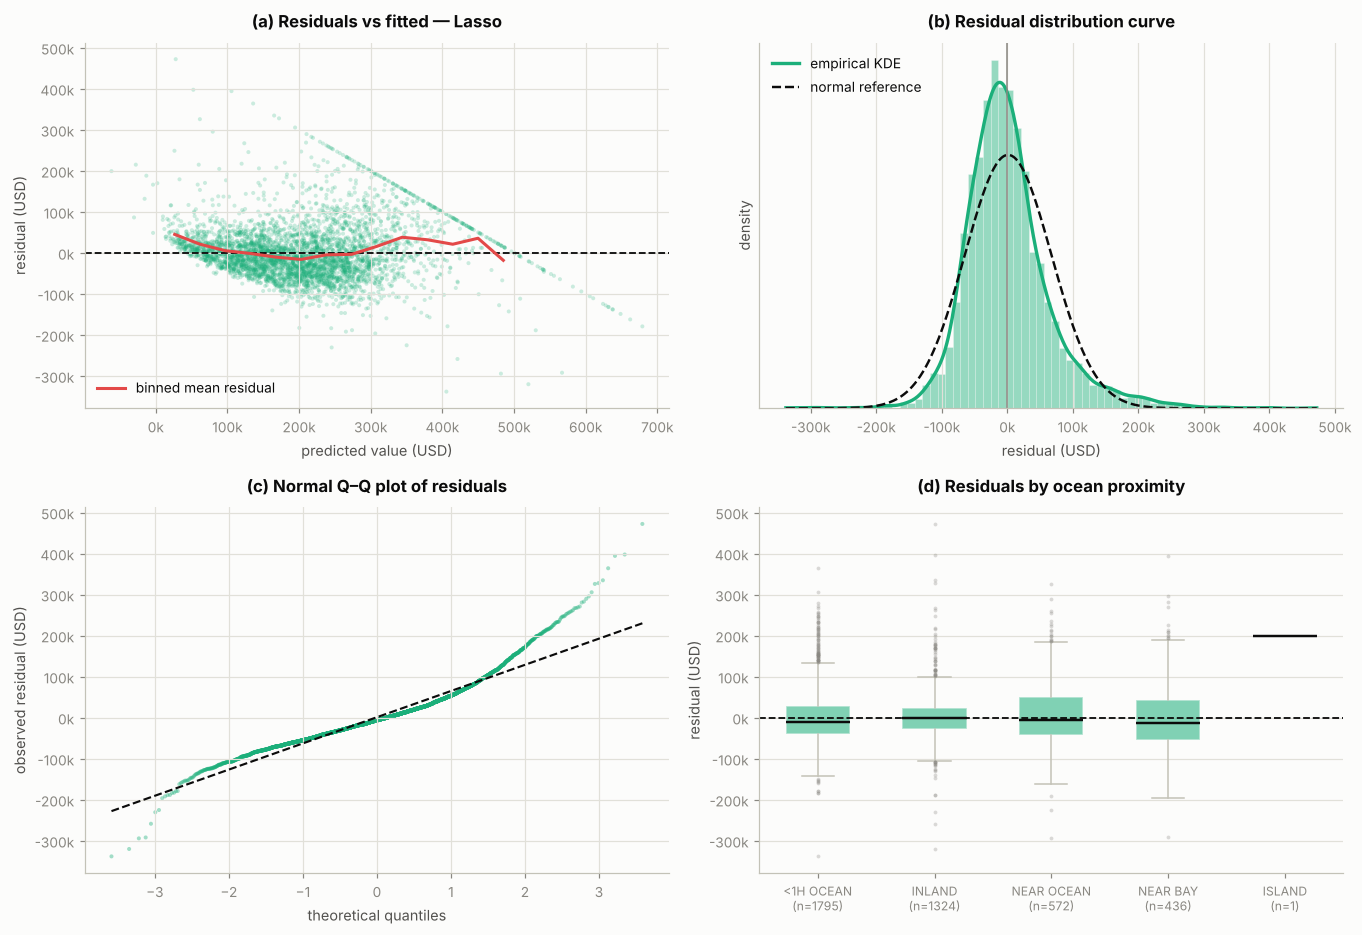

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.6))
color = MODEL_COLOR[best_name]

# (a) residuals vs fitted ----------------------------------------------------
ax = axes[0, 0]
ax.scatter(best_pred, best_resid, s=7, alpha=0.22, color=color,
           edgecolors="none", rasterized=True)
ax.axhline(0, color=INK, linewidth=1.2, linestyle="--")
bins = np.linspace(best_pred.min(), best_pred.max(), 22)
idx = np.digitize(best_pred, bins)
centres = [(bins[i-1]+bins[i])/2 for i in range(1, len(bins))]
means = [best_resid[idx == i].mean() if (idx == i).sum() > 15 else np.nan
         for i in range(1, len(bins))]
ax.plot(centres, means, color=POS, linewidth=2, label="binned mean residual")
ax.set_title(f"(a) Residuals vs fitted — {best_name}")
ax.set_xlabel("predicted value (USD)"); ax.set_ylabel("residual (USD)")
ax.xaxis.set_major_formatter(thousands); ax.yaxis.set_major_formatter(thousands)
ax.legend(loc="lower left")

# (b) residual distribution + normal reference -------------------------------
ax = axes[0, 1]
ax.hist(best_resid, bins=70, density=True, color=color, alpha=0.45,
        edgecolor=SURFACE, linewidth=0.4)
xs = np.linspace(best_resid.min(), best_resid.max(), 400)
kde = stats.gaussian_kde(best_resid)
ax.plot(xs, kde(xs), color=color, linewidth=2.2, label="empirical KDE")
ax.plot(xs, stats.norm.pdf(xs, best_resid.mean(), best_resid.std()),
        color=INK, linewidth=1.6, linestyle="--", label="normal reference")
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_title("(b) Residual distribution curve")
ax.set_xlabel("residual (USD)"); ax.set_ylabel("density")
ax.xaxis.set_major_formatter(thousands)
ax.set_yticks([])
ax.legend(loc="upper left")

# (c) Q-Q plot ---------------------------------------------------------------
ax = axes[1, 0]
(osm, osr), (slope, intercept, r) = stats.probplot(best_resid, dist="norm")
ax.scatter(osm, osr, s=7, alpha=0.4, color=color, edgecolors="none", rasterized=True)
ax.plot(osm, slope*osm + intercept, color=INK, linewidth=1.4, linestyle="--")
ax.set_title("(c) Normal Q–Q plot of residuals")
ax.set_xlabel("theoretical quantiles"); ax.set_ylabel("observed residual (USD)")
ax.yaxis.set_major_formatter(thousands)

# (d) residuals by category --------------------------------------------------
ax = axes[1, 1]
cats = X_test["ocean_proximity"].values
order = [c for c in ["<1H OCEAN", "INLAND", "NEAR OCEAN", "NEAR BAY", "ISLAND"]
         if (cats == c).sum() > 0]
data = [best_resid[cats == c] for c in order]
bp_ = ax.boxplot(data, vert=True, patch_artist=True, widths=0.55,
                 flierprops=dict(marker="o", markersize=2.5, alpha=0.3,
                                 markerfacecolor=MUTED, markeredgecolor="none"),
                 medianprops=dict(color=INK, linewidth=1.6),
                 whiskerprops=dict(color=AXIS), capprops=dict(color=AXIS))
for patch in bp_["boxes"]:
    patch.set_facecolor(color); patch.set_alpha(0.55); patch.set_edgecolor(SURFACE)
ax.axhline(0, color=INK, linewidth=1.2, linestyle="--")
ax.set_xticks(range(1, len(order)+1),
              [f"{c}\n(n={int((cats==c).sum())})" for c in order], fontsize=8)
ax.set_title("(d) Residuals by ocean proximity")
ax.set_ylabel("residual (USD)"); ax.yaxis.set_major_formatter(thousands)
ax.grid(axis="x", visible=False)

plt.tight_layout(); plt.show()

### Diagnostics, panel by panel

**(a) Residuals vs fitted.** The binned mean (red) is **U-shaped, not flat**: it sits around
+\$29k in the lowest fitted decile, dips to about −\$17k through the middle, and climbs back
to roughly +\$20k at the top. So the model under-predicts at both extremes of its own output
range and mildly over-predicts the middle — unmodelled curvature, not random scatter.
Separately, the vertical spread grows steadily with the fitted value, from a residual SD of
about \$43k in the second decile to about \$85k in the top one. That is textbook
**heteroscedasticity**, confirmed by the Breusch–Pagan test above (p ≈ 4e−22). Consequence:
the point predictions remain usable, but ordinary standard errors and confidence intervals
would be understated.

**(b) Residual distribution.** The KDE is taller and narrower in the middle than the normal
reference, with a long **right** tail (skewness +1.04). The right tail is the \$500k-capped
districts: because residual = actual − predicted and the model cannot predict past the cap,
those districts carry large *positive* residuals, averaging +\$102k and reaching +\$472k.
Excess kurtosis of +3.9 confirms heavier-than-normal tails on both sides.

**(c) Q–Q plot.** Points track the line through the middle of the distribution and bend away
at both ends, with the **upper** end pulling further off the line than the lower — the
signature of heavy tails combined with the right skew the capped districts introduce.

**(d) Residuals by category.** Medians fall within about \$13k of zero for all four
substantial categories — small against a residual SD near \$66k — so the one-hot encoding is
doing its job and no group is badly mispriced, though the coastal categories are
over-predicted very slightly. `INLAND` has the tightest spread (IQR ≈ \$52k — cheaper, more
homogeneous districts) and `NEAR BAY` the widest (IQR ≈ \$98k). `ISLAND` has a single test
record and cannot be interpreted.

### Residual distributions compared across all three models

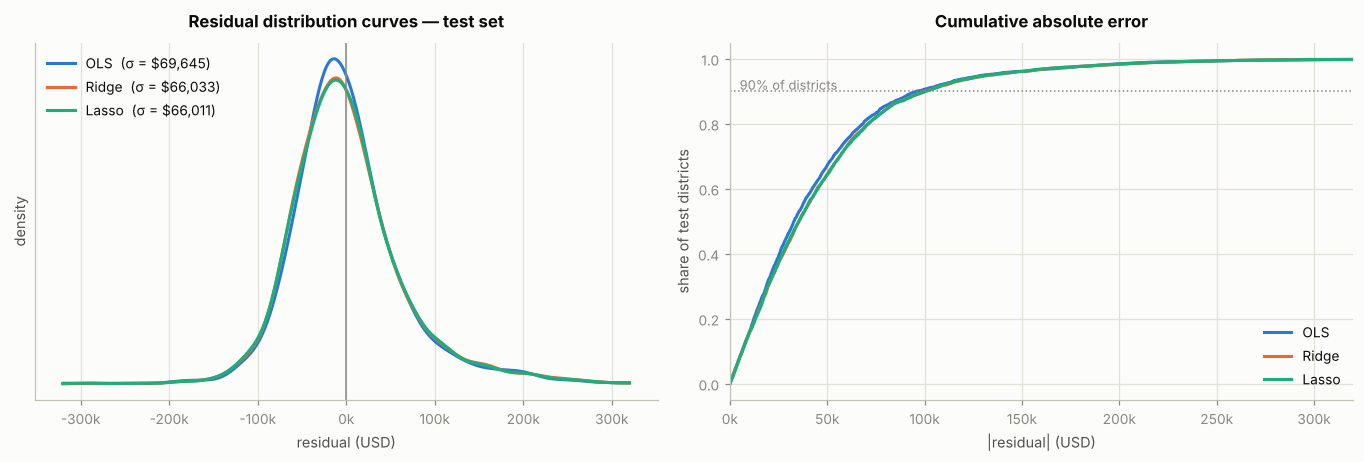

Absolute error — percentiles and the single worst miss:
           p50       p90       p99 worst error
OLS    $32,900   $95,798  $218,340  $1,655,197
Ridge  $35,491   $99,905  $228,823    $466,862
Lasso  $35,419  $100,518  $225,735    $472,227

OLS's 5 worst districts alone account for 17.4% of its total squared error.
On its single worst district OLS misses by $1,655,197; Lasso misses the same district by $5,341.


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
xs = np.linspace(-320_000, 320_000, 500)
for name in models:
    r = resid[name]
    ax.plot(xs, stats.gaussian_kde(r)(xs), color=MODEL_COLOR[name],
            label=f"{name}  (σ = ${r.std():,.0f})")
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_title("Residual distribution curves — test set")
ax.set_xlabel("residual (USD)"); ax.set_ylabel("density")
ax.xaxis.set_major_formatter(thousands); ax.set_yticks([])
ax.legend(loc="upper left")

ax = axes[1]
for name in models:
    r = np.sort(np.abs(resid[name]))
    ax.plot(r, np.linspace(0, 1, len(r)), color=MODEL_COLOR[name], label=name)
ax.axhline(0.9, color=MUTED, linewidth=1, linestyle=":")
ax.text(5_000, 0.905, "90% of districts", color=MUTED, fontsize=8.5)
ax.set_title("Cumulative absolute error")
ax.set_xlabel("|residual| (USD)"); ax.set_ylabel("share of test districts")
ax.xaxis.set_major_formatter(thousands)
ax.set_xlim(0, 320_000)
ax.legend(loc="lower right")

plt.tight_layout(); plt.show()

err = pd.DataFrame({n: np.percentile(np.abs(resid[n]), [50, 90, 99]) for n in models},
                   index=["p50", "p90", "p99"]).T
err["worst error"] = [np.abs(resid[n]).max() for n in models]
print("Absolute error — percentiles and the single worst miss:")
print(err.map(lambda v: f"${v:,.0f}").to_string())

worst5 = np.argsort(np.abs(resid["OLS"]))[::-1][:5]
share = (resid["OLS"][worst5]**2).sum() / (resid["OLS"]**2).sum()
print(f"\nOLS's 5 worst districts alone account for {share:.1%} of its total squared error.")
print(f"On its single worst district OLS misses by ${np.abs(resid['OLS'][worst5[0]]):,.0f}; "
      f"Lasso misses the same district by ${np.abs(resid['Lasso'][worst5[0]]):,.0f}.")

**This is the most important plot for understanding why the metrics disagreed, and it
cuts against the obvious reading.** The three residual curves are nearly
indistinguishable, and the cumulative-error panel shows OLS is in fact *marginally better*
than the penalised models across almost the entire distribution — at the median, at the
90th percentile (≈ \$96k vs ≈ \$100k), even at the 99th.

So where did OLS lose \$3,600 of RMSE? In a handful of districts beyond the 99th percentile.
OLS's worst single miss is about **\$1.66 million** — a prediction wilder than any actual
house value in the dataset — while Lasso's worst miss is about \$472k. Those five worst
districts alone contribute roughly **17% of OLS's entire squared error**, and on its very
worst district Lasso is off by only about \$5k where OLS is off by \$1.66M.

That is the whole story of the RMSE/MAE disagreement in one number. Regularisation here did
not make typical predictions better — it made *catastrophic* predictions impossible, by
refusing to let collinear features carry enormous cancelling weights. Whether that is worth
a slightly higher typical error depends entirely on how costly a single large mistake is.

## 17. Conclusions

In [31]:
summary = comparison[["Test RMSE", "Test MAE", "Test R2", "R2 gap"]].copy()
summary["α"] = ["—", f"{ridge_alpha:,.3f}", f"{lasso_alpha:.6f}"]
summary["features used"] = [coef_table[m]["features used"] for m in models]
summary.style.format({"Test RMSE": "${:,.0f}", "Test MAE": "${:,.0f}",
                      "Test R2": "{:.4f}", "R2 gap": "{:.4f}"})

,Test RMSE,Test MAE,Test R2,R2 gap,α,features used
OLS,"$69,662","$45,986",0.6297,0.0945,—,81
Ridge,"$66,043","$47,428",0.6671,0.0259,228.546,81
Lasso,"$66,021","$47,416",0.6674,0.0284,0.001528,37


### In short

**Regularisation helped, and it helped because the features were collinear.** After a
degree-2 interaction expansion the design matrix held 81 heavily overlapping features.
Plain OLS responded with enormous, cancelling coefficients (largest |β| ≈ 28 in
standardised units) and overfitted — R² 0.72 on training data, 0.63 on test. Both
penalties fixed that: Ridge and Lasso land near R² 0.67 on test with a train/test gap a
fraction of OLS's, and both cut about \$3,600 off test RMSE.

**Ridge and Lasso ended up almost tied, but they are not interchangeable.** Ridge kept all
81 features and shrank every weight below 0.3 — the better choice when correlated features
should share credit. Lasso reached the same accuracy using roughly half the features,
zeroing the rest outright — the better choice when a compact, explainable model matters.
On cross-validated RMSE, Lasso was selected here.

**Which metric you trust changes the verdict, and the reason is narrower than it looks.**
OLS has the *lowest* MAE, and it is actually slightly more accurate than Ridge or Lasso
right out to the 99th percentile of absolute error. Its entire RMSE penalty comes from a
handful of extreme failures — one district missed by \$1.66 million, with its five worst
districts contributing about 17% of its total squared error. Regularisation did not improve
typical predictions here; it eliminated the catastrophic ones. For valuation work, where a
single wildly mispriced property is far more costly than a slightly larger typical error,
that trade is worth making and RMSE is the metric to select on.

**The residuals say the remaining error is structural, not a tuning problem.** Three things
show up clearly: the target is censored at \$500,001 (4.7% of districts, which no model can
predict past, and which produce the long right tail in the residual distribution); the error
variance roughly doubles from the cheapest fitted decile to the most expensive
(Breusch–Pagan p ≈ 4e−22); and the bias runs monotonically from over-predicting the cheapest
decile by about \$20k to under-predicting the dearest by about \$99k. A linear model — even
one carrying every pairwise interaction — cannot bend to the real price surface.

**Where the next gain would come from:** model `log(median_house_value)` instead of raw
dollars to stabilise the variance and remove negative predictions; drop or model the capped
districts separately; and compare against a tree ensemble, which handles the non-linear
geographic structure without being told which interactions to build.